# Model 3 · Experiments: Pipeline 3 (Cantonese voice notes)

**Pipeline 3** lets the cook speak the request instead of typing it. A Hugging Face
`automatic-speech-recognition` pipeline turns the voice note into Cantonese text, which lands in the
request box (still editable) and then goes through Pipeline 1 and Pipeline 2.

Good Cantonese speech models already exist on the Hub, so this pipeline is **not fine-tuned**: we test
three pre-trained models on our own test set and pick one on **accuracy and run time**.

Steps in this notebook
1. Load 200 Cantonese voice clips with human transcripts (Common Voice 22, test split).
2. Transcribe them with three candidate models through the app's own `Transcriber` class.
3. Compare character accuracy and run time; pick one.
4. Record the results for `Experimental_results.xlsx`.

## 0 · Setup

In [ ]:
# Runs in Colab ("Restart & Run All") and locally. Clones the project if it is not already here.
import gc, json, os, random, subprocess, sys, time, warnings
from pathlib import Path

REPO_URL = "https://github.com/Tannedfish/same-table.git"
here = Path.cwd()
if not any((p / "same_table").is_dir() for p in (here, here.parent)):
    if Path("same-table/.git").is_dir():                      # an earlier Colab clone: refresh it
        subprocess.run(["git", "-C", "same-table", "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "same-table"], check=True)
    os.chdir("same-table")
elif (here / ".git").is_dir() and str(here).startswith("/content"):   # re-run inside the Colab clone
    subprocess.run(["git", "pull", "--ff-only"], check=False)
ROOT = Path.cwd() if (Path.cwd() / "same_table").is_dir() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

REQUIRED = ["scripts/make_training_data.py", "same_table/library.py", "data/library.json"]
missing = [f for f in REQUIRED if not (ROOT / f).exists()]
if missing:
    raise FileNotFoundError(f"{ROOT} is an old copy of the project (missing: {', '.join(missing)}). "
                            "Push the latest project to GitHub, delete this folder and run all cells again.")

try:
    import datasets, sentence_transformers, sklearn, transformers  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets",
                    "sentence-transformers", "scikit-learn", "accelerate", "openpyxl"], check=True)

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)

DATA, OUT = ROOT / "data" / "train", ROOT / "artifacts"
OUT.mkdir(exist_ok=True)
HF_USER = "Tannedfish95"            # Hugging Face username that owns the fine-tuned model
SEED = 5240

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]

set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.11.0+cu130


## 1 · Test set

`scripts/make_speech_testset.py` takes the Cantonese (`yue`) **test** split of Mozilla Common Voice 22
(CC0 licence, on the Hub as `JackyHoCL/common_voice_22_yue`), keeps clips with at least two up-votes and
no down-votes, and draws 200 with a fixed seed, at most two per speaker. The clips are everyday Cantonese
sentences read by volunteers: harder than a cook's short request, and none of them was used to train
our models.

In [ ]:
from same_table.speech import SAMPLE_RATE, char_errors, normalize_transcript
import soundfile as sf

SPEECH = ROOT / "data" / "speech"
if not (SPEECH / "cv22_yue_test200.jsonl").exists():
    done = subprocess.run([sys.executable, str(ROOT / "scripts" / "make_speech_testset.py")], capture_output=True, text=True)
    if done.returncode:
        raise RuntimeError("make_speech_testset.py failed:\n" + done.stderr[-2000:])

clips = read_jsonl(SPEECH / "cv22_yue_test200.jsonl")
audio = [sf.read(SPEECH / c["file"], dtype="float32")[0] for c in clips]
seconds = np.array([c["seconds"] for c in clips])
print(f"{len(clips)} clips | {len({c['speaker'] for c in clips})} speakers | {seconds.sum() / 60:.1f} minutes | "
      f"median {np.median(seconds):.1f} s | {sum(len(c['sentence']) for c in clips)} reference characters")
pd.DataFrame(clips[:5])[["sentence", "seconds", "speaker"]]

200 clips | 167 speakers | 15.2 minutes | median 4.4 s | 2085 reference characters


,sentence,seconds,speaker
0,相思歸去日已暮,5.80,b37992c7eb95
1,任何人，無論你尋日幾風光，今日都可能身敗名裂,7.31,89c00e61e3ec
2,然後搞到自己一身蟻,4.03,4343712995f9
3,阿拉伯人好靚啊,3.78,d4b8aa1abc81
4,依家出街唔使睇綠碼,4.00,1878963f84d2


## 2 · Three pre-trained speech models

| | Model | Architecture | Size |
|---|---|---|---|
| Model 1 | `alvanlii/whisper-small-cantonese` | Whisper small, fine-tuned on Cantonese by its author | 242 M |
| Model 2 | `safecantonese/whisper-base-yue-hk-mdccl` | Whisper base, fine-tuned on Hong Kong Cantonese | 73 M |
| Model 3 | `scottykwok/wav2vec2-large-xlsr-cantonese` | wav2vec2 XLSR + CTC, fine-tuned on Cantonese | 315 M |

Whisper models decode greedily with the language fixed to Chinese (`zh`), which is how the app runs them.

**Metrics.** *Character accuracy* = 1 − character error rate over all 200 clips (edits ÷ reference
characters; punctuation, spaces and simplified/traditional differences are ignored). *Sentence accuracy*
= clips transcribed with no error at all. *Run time* = seconds per clip on CPU, as on Streamlit Cloud.

In [ ]:
from dataclasses import replace
from same_table.config import Settings
from same_table.speech import Transcriber

P3_CANDIDATES = {   # model id -> language setting used by the app
    "alvanlii/whisper-small-cantonese": "zh",
    "safecantonese/whisper-base-yue-hk-mdccl": "zh",
    "scottykwok/wav2vec2-large-xlsr-cantonese": "",
}
base_settings = replace(Settings.load(), offline=False)
refs = [c["sentence"] for c in clips]
p3_results, p3_outputs = {}, {}

for model_id, language in P3_CANDIDATES.items():
    transcriber = Transcriber(replace(base_settings, p3_model_id=model_id, p3_language=language)).load()
    assert transcriber.available, transcriber.error
    transcriber.transcribe_array(audio[0])                        # warm up
    t0 = time.perf_counter()
    hyps = [transcriber.transcribe_array(a) for a in audio]       # exactly what the app runs
    run_seconds = time.perf_counter() - t0
    errs = np.array([char_errors(r, h) for r, h in zip(refs, hyps)])
    per_clip_acc = 1 - errs[:, 0] / np.maximum(errs[:, 1], 1)
    p3_outputs[model_id] = {"hypotheses": hyps, "edits": errs[:, 0].tolist(), "chars": errs[:, 1].tolist()}
    p3_results[model_id] = {
        "char_accuracy": float(1 - errs[:, 0].sum() / errs[:, 1].sum()),
        "sentence_accuracy": float((errs[:, 0] == 0).mean()),
        "char_accuracy_se": float(per_clip_acc.std(ddof=1) / np.sqrt(len(clips))),
        "seconds_per_clip": run_seconds / len(clips),
        "real_time_factor": run_seconds / seconds.sum(),
        "params_M": sum(p.numel() for p in transcriber._pipe.model.parameters()) / 1e6,
    }
    print(model_id, {k: round(v, 3) for k, v in p3_results[model_id].items()})
    del transcriber; gc.collect()

config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/4.29k [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/45.1k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

scottykwok/wav2vec2-large-xlsr-cantonese {'char_accuracy': 0.723, 'sentence_accuracy': 0.08, 'char_accuracy_se': 0.012, 'seconds_per_clip': 0.096, 'real_time_factor': np.float64(0.021), 'params_M': 319.083}


## 3 · Model selection: accuracy and run time

Same rule as the other pipelines: highest **character accuracy**; models within one standard error of
the best are treated as tied, and the shortest run time wins.

In [ ]:
p3_table = pd.DataFrame(p3_results).T[["char_accuracy", "sentence_accuracy", "seconds_per_clip",
                                       "real_time_factor", "params_M"]].round(3)
best = p3_table.char_accuracy.max()
standard_error = p3_results[p3_table.char_accuracy.idxmax()]["char_accuracy_se"]
close = p3_table[p3_table.char_accuracy >= best - standard_error]
P3_CHOSEN = close.seconds_per_clip.idxmin()
print(f"best character accuracy {best:.3f}, standard error {standard_error:.3f} -> tied: {list(close.index)}")
print("Picked:", P3_CHOSEN)
p3_table

best character accuracy 0.920, standard error 0.010 -> tied: ['alvanlii/whisper-small-cantonese']
Picked: alvanlii/whisper-small-cantonese


,char_accuracy,sentence_accuracy,seconds_per_clip,real_time_factor,params_M
alvanlii/whisper-small-cantonese,0.920,0.585,0.381,0.084,241.735
safecantonese/whisper-base-yue-hk-mdccl,0.832,0.305,0.163,0.036,72.594
scottykwok/wav2vec2-large-xlsr-cantonese,0.723,0.080,0.096,0.021,319.083


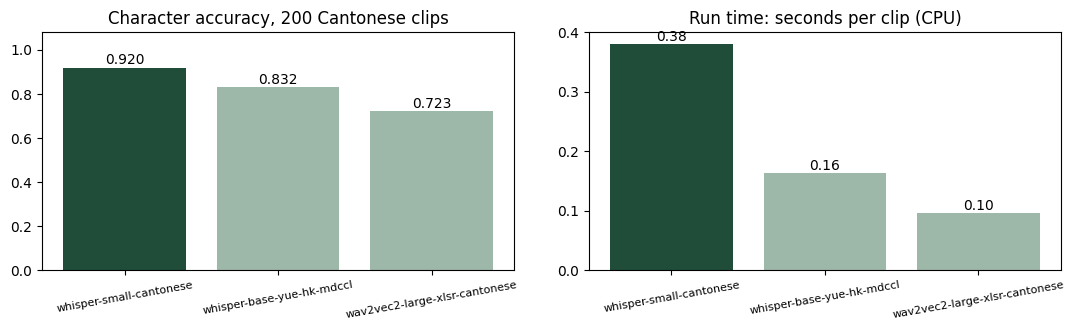

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
short = [m.split("/")[-1] for m in p3_table.index]
colors = ["#1F4D3A" if m == P3_CHOSEN else "#9DB8A9" for m in p3_table.index]
ax[0].bar(short, p3_table.char_accuracy, color=colors); ax[0].set_ylim(0, 1.08)
ax[0].set_title("Character accuracy, 200 Cantonese clips")
for x, v in enumerate(p3_table.char_accuracy): ax[0].text(x, v + 0.015, f"{v:.3f}", ha="center")
ax[1].bar(short, p3_table.seconds_per_clip, color=colors); ax[1].set_title("Run time: seconds per clip (CPU)")
for x, v in enumerate(p3_table.seconds_per_clip): ax[1].text(x, v, f"{v:.2f}", ha="center", va="bottom")
for a in ax: a.tick_params(axis="x", labelsize=8, rotation=10)
plt.tight_layout(); plt.savefig(OUT / "p3_comparison.png", dpi=150); plt.show()

In [ ]:
# What the picked model gets wrong: the 10 clips with the most character errors
picked = p3_outputs[P3_CHOSEN]
worst = np.argsort(-np.array(picked["edits"]))[:10]
pd.DataFrame({"reference": [refs[i] for i in worst], "heard": [picked["hypotheses"][i] for i in worst],
              "errors": [picked["edits"][i] for i in worst], "characters": [picked["chars"][i] for i in worst]})

,reference,heard,errors,characters
0,你哋攞咩嘢軟件查正字？,你哋我咩願檢查政治,6,10
1,謝手謝腳，形容做嘢冇氣冇力，唔出力,這手這腳，形容做嘢武器武力，唔出力,5,15
2,用邊張信用卡好呢？,用邊樣上靠呢？,5,8
3,阿姐話首先要夾夾生肖,阿姐話首先要急急身潮,4,10
4,但係枝蠟燭熄咗,但係支立足識咗,4,7
5,可唔可以幫我解決下問題啊,我唔可以夢和解決下問題呀,4,12
6,定係你想叫返情趣小蟋蟀,定係你想叫返程序小識術？,4,11
7,之後，錄錄吓見夜咗,之後六六下見夜咗,3,8
8,噉都有得詏？,咁多有得咬？,3,5
9,第一個嚟到就車得走嘅點同大將軍交代,第一個嚟到就請得走嘅點同大象玩交代,3,17


## 4 · Record the results

The voice-note rows of the whole-app test are filled in by hand on the deployed app (record the five
suggested requests in the Excel sheet). Run this notebook before `Model2_experiments.ipynb` writes the
Excel file, or re-run `python scripts/export_results.py` afterwards.

In [ ]:
(OUT / "experiments_speech.json").write_text(json.dumps({
    "candidates": P3_CANDIDATES, "results": p3_results, "chosen": P3_CHOSEN,
    "counts": {"clips": len(clips), "speakers": len({c['speaker'] for c in clips}), "minutes": round(seconds.sum() / 60, 1),
               "reference_characters": int(sum(p3_outputs[P3_CHOSEN]["chars"]))},
    "clips": [{"file": c["file"], "reference": c["sentence"]} for c in clips], "outputs": p3_outputs,
    "device": DEVICE}, ensure_ascii=False, indent=1), encoding="utf-8")
if (OUT / "experiments.json").exists() and (OUT / "p1_results.json").exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "export_results.py")], check=True)
    print("updated", OUT / "Experimental_results.xlsx")
print(f'''
# Streamlit Cloud -> Settings -> Secrets (only needed if the pick differs from the default in same_table/config.py)
P3_MODEL_ID = "{P3_CHOSEN}"
P3_LANGUAGE = "{P3_CANDIDATES[P3_CHOSEN] or 'none'}"
''')

updated /content/same-table/artifacts/Experimental_results.xlsx

# Streamlit Cloud -> Settings -> Secrets (only needed if the pick differs from the default in same_table/config.py)
P3_MODEL_ID = "alvanlii/whisper-small-cantonese"
P3_LANGUAGE = "zh"

